In [1]:
import pandas as pd
import numpy as np

DATA = "/kaggle/input/competitions/dsai-club-induction-2026-sy-task"
train = pd.read_csv(DATA + "/competition_train.csv")
test = pd.read_csv(DATA + "/competition_test.csv")

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
print(train.shape, test.shape)
print(train.isna().sum())



(127657, 8) (31914, 2)
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


Loaded train and test with guven csv files. Train has all cols including labels while test has only id and comment_text.

toxic            0.096383
severe_toxic     0.009956
obscene          0.053244
threat           0.003000
insult           0.049280
identity_hate    0.009040
dtype: float64


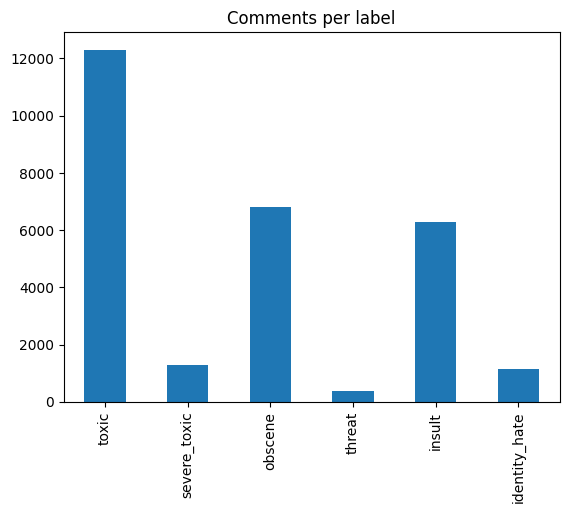

n_labels
0    114604
1      5131
3      3349
2      2815
4      1423
5       310
6        25
Name: count, dtype: int64
count    127657.000000
mean        393.445624
std         591.135961
min           6.000000
25%          95.000000
50%         205.000000
75%         434.000000
max        5000.000000
Name: length, dtype: float64
             mean  median
toxic                    
0      404.120621   216.0
1      293.364922   124.0


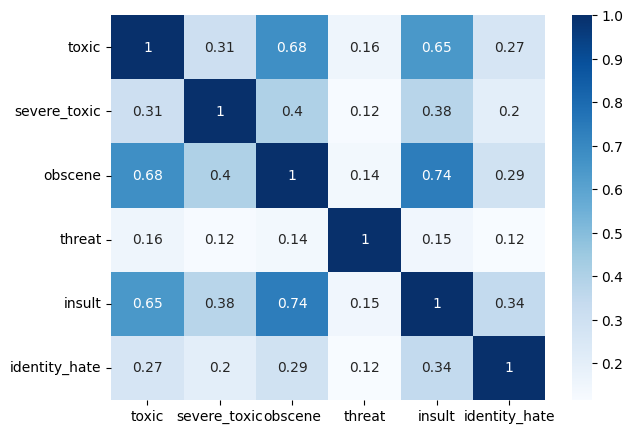

Sieg Heil! 

Heil Hitler you gay noob!! I'm gonna cut off your brain!
-----
"
Christians
What about all the idiot Christians who will come on this page and claim that this thing never existed and they'll just change the article to one big ""GOOOOOOOOOOOOOOD DIIIIIIIIIIID IIIIIIIIIIIIT""? Fucking stupid Christians, they believe dinosaurs didn't exist and their whole ignorant
-----
You are such a fucking hypocrite. 

I hope you get raped and killed by some lunatic like Andrew Morrow.
-----


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

print(train[LABELS].mean())
train[LABELS].sum().plot(kind="bar", title="Comments per label")
plt.show()

train["n_labels"] = train[LABELS].sum(axis=1)
print(train["n_labels"].value_counts())

train["length"] = train["comment_text"].str.len()
print(train["length"].describe())
print(train.groupby("toxic")["length"].agg(["mean", "median"]))

plt.figure(figsize=(7, 5))
sns.heatmap(train[LABELS].corr(), annot=True, cmap="Blues")
plt.show()

for text in train[train["threat"] == 1]["comment_text"].head(3):
    print(text[:300])
    print("-----")

Made a chart to observe how common each comment is. Threat,identity hate and severe toxic are rare. Toxic is the most common. Most comments have zero labels, but some have more labels. Comment length is right-skewed (mean 393, median 205, max 5000). Toxic comments are shorter on average (293 characters) than clean ones (404). Toxic, obscene, and insult labels are strongly related. Reading some examples for analysis. Many swears and capital letters.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.sparse import hstack

X = train["comment_text"]
Y = train[LABELS]

X_tr, X_val, Y_tr, Y_val = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=train["toxic"]
)
print(len(X_tr), len(X_val))

102125 25532


Split train data as 80/20. 20% was used for validation.

In [4]:
def fit_and_score(Xtr_mat, Xval_mat, C=1.0):
    scores = {}
    preds = pd.DataFrame(index=Y_val.index)
    for label in LABELS:
        model = LogisticRegression(C=C, solver="liblinear")
        model.fit(Xtr_mat, Y_tr[label])
        preds[label] = model.predict_proba(Xval_mat)[:, 1]
        scores[label] = roc_auc_score(Y_val[label], preds[label])
    print(pd.Series(scores))
    print("MEAN AUC:", np.mean(list(scores.values())))
    return preds

# Baseline: word TF-IDF only
word_vec = TfidfVectorizer(max_features=50000, stop_words="english")
Xtr_w = word_vec.fit_transform(X_tr)
Xval_w = word_vec.transform(X_val)
baseline_preds = fit_and_score(Xtr_w, Xval_w)

toxic            0.968856
severe_toxic     0.981145
obscene          0.983936
threat           0.976569
insult           0.977583
identity_hate    0.971634
dtype: float64
MEAN AUC: 0.9766206369723686


Models only understand numbers, not words. So we convert text to numbers with TF-IDF. TF is term frequency, ie how often a certain term appears. IDF is inverse document frequency, ie how rare a term is across all comments.

In [5]:
word_vec = TfidfVectorizer(max_features=100000, ngram_range=(1, 2),
                           sublinear_tf=True, strip_accents="unicode")
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                           max_features=200000, sublinear_tf=True)

Xtr_w = word_vec.fit_transform(X_tr)
Xval_w = word_vec.transform(X_val)
Xtr_c = char_vec.fit_transform(X_tr)
Xval_c = char_vec.transform(X_val)

Xtr_comb = hstack([Xtr_w, Xtr_c]).tocsr()
Xval_comb = hstack([Xval_w, Xval_c]).tocsr()

improved_preds = fit_and_score(Xtr_comb, Xval_comb, C=4.0)

toxic            0.979284
severe_toxic     0.987521
obscene          0.989952
threat           0.990596
insult           0.982197
identity_hate    0.984568
dtype: float64
MEAN AUC: 0.9856863435709614


Toxic comments are full of misspellings and disguised swear words. Character n-grams look at chunks of 2-5 letters, so they still catch the pattern.

In [6]:
for C in [2]:
    print("=== C =", C)
    fit_and_score(Xtr_comb, Xval_comb, C=C)

=== C = 2
toxic            0.979763
severe_toxic     0.988155
obscene          0.990133
threat           0.990715
insult           0.983396
identity_hate    0.985223
dtype: float64
MEAN AUC: 0.986230807783197


C controls how closely the model fits the training data. C=2 gives best AUC.

In [7]:
BEST_C = 2.0   # replace with your best C from Cell 6

word_vec = TfidfVectorizer(max_features=100000, ngram_range=(1, 2),
                           sublinear_tf=True, strip_accents="unicode")
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                           max_features=200000, sublinear_tf=True)

X_all = hstack([word_vec.fit_transform(train["comment_text"]),
                char_vec.fit_transform(train["comment_text"])]).tocsr()
X_test = hstack([word_vec.transform(test["comment_text"]),
                 char_vec.transform(test["comment_text"])]).tocsr()

submission = pd.DataFrame({"id": test["id"]})
for label in LABELS:
    model = LogisticRegression(C=BEST_C, solver="liblinear")
    model.fit(X_all, train[label])
    submission[label] = model.predict_proba(X_test)[:, 1]

submission.to_csv("/kaggle/working/submission2.csv", index=False)

Model	                                  Mean AUC

Baseline (word TF-IDF + LR)	              0.9766

char n-grams	                          0.9857

tuned C	                                  0.9862

leaderboard                               0.9870

In [11]:
import os
print(submission.shape)
submission.to_csv("/kaggle/working/submission.csv", index=False)
print(os.path.exists("/kaggle/working/submission.csv"))

(31914, 7)
True


In [10]:
sample = pd.read_csv(DATA + "/sample_submission.csv")
print(submission.shape, sample.shape)
print(submission.columns.tolist() == sample.columns.tolist())
print((submission["id"] == sample["id"]).all())
print(submission.isna().sum().sum())
print(submission[LABELS].min().min(), submission[LABELS].max().max())

(31914, 7) (31914, 7)
True
True
0
2.818347265766213e-05 0.9999999999748697
